In [1]:
# 1. Import libraries

import geopandas as gpd
import matplotlib.pyplot as plt

KM = 1000

In [2]:
# 2. Read river

indus = gpd.read_file("Indus_River.geojson")

indus.head()

,rivname,rilcode,origin,major_trib,bacode,ba_name,sub_basin,remarks,st_length_,geometry
0,Indus,1,None,None,01,Indus (Up to border),None,ok,890146.827789,"LINESTRING (75.34459 35.53277, 75.34237 35.553..."


In [3]:
# 3. Check data

print("Shape:", indus.shape)
print("\nGeometry type:")
print(indus.geom_type.value_counts())

print("\nCRS:")
print(indus.crs)

print("\nBounds:")
print(indus.total_bounds)

print("\nColumns:")
print(indus.columns)

Shape: (1, 10)

Geometry type:
LineString    1
Name: count, dtype: int64

CRS:
EPSG:4326

Bounds:
[74.72631932 35.53277005 75.34459034 35.8508183 ]

Columns:
Index(['rivname', 'rilcode', 'origin', 'major_trib', 'bacode', 'ba_name',
       'sub_basin', 'remarks', 'st_length_', 'geometry'],
      dtype='str')


In [4]:
# 4. Reproject to a CRS with metre units

indus = indus.to_crs("EPSG:32643")

print("Projected CRS:")
print(indus.crs)

# Compare stored length attribute with length computed from geometry
print("\nComputed length (km):", round(indus.length.sum() / KM, 2))
print("Stored st_length_ (km):", round(indus["st_length_"].sum() / KM, 2))

Projected CRS:
EPSG:32643

Computed length (km): 87.41
Stored st_length_ (km): 890.15


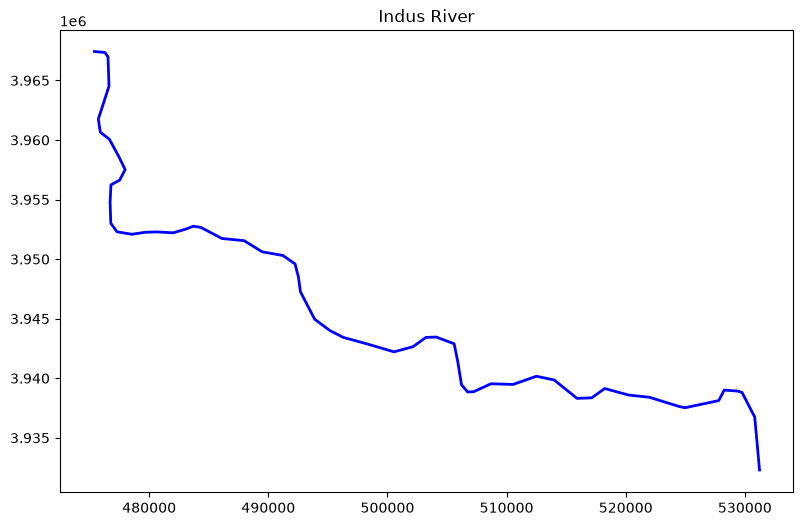

In [5]:
# Check river

fig, ax = plt.subplots(figsize=(10, 6))

indus.plot(
    ax=ax,
    color="blue",
    linewidth=2
)

ax.set_title("Indus River")
plt.show()

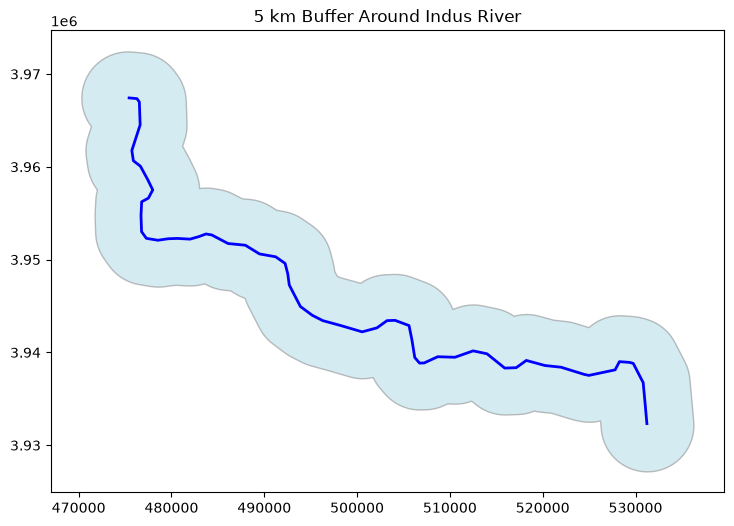

In [6]:
# 5. Create 5 km buffer

buffer_5km = indus.buffer(5 * KM)

fig, ax = plt.subplots(figsize=(10, 6))

buffer_5km.plot(
    ax=ax,
    color="lightblue",
    edgecolor="gray",
    alpha=0.5
)

indus.plot(
    ax=ax,
    color="blue",
    linewidth=2
)

ax.set_title("5 km Buffer Around Indus River")
plt.show()

In [7]:
# 6. Read settlements

settlements = gpd.read_file(
    "Indus_Settlements.geojson"
)

# Remove the pre-computed answer so we calculate it ourselves
settlements = settlements.drop(columns="Within_5km", errors="ignore")

print(settlements.head())
print("\nShape:", settlements.shape)
print("\nGeometry type:")
print(settlements.geom_type.value_counts())
print("\nCRS:")
print(settlements.crs)

     Settlement  Population     Type                   geometry
0  Settlement_A        1200  Village  POINT (75.32016 35.55476)
1  Settlement_B        2500  Village  POINT (75.37869 35.65165)
2  Settlement_C         850  Village  POINT (75.29358 35.55659)
3  Settlement_D        4200     Town   POINT (75.26132 35.6777)
4  Settlement_E        1600  Village     POINT (75.21473 35.56)

Shape: (20, 4)

Geometry type:
Point    20
Name: count, dtype: int64

CRS:
EPSG:4326


In [8]:
# Reproject settlements to the same CRS as the river

settlements = settlements.to_crs(
    indus.crs
)

print("Settlement CRS:")
print(settlements.crs)

Settlement CRS:
EPSG:32643


In [9]:
# 7. Proximity analysis

settlements["Dist_km"] = (
    settlements.distance(indus.union_all()) / KM
).round(2)

settlements["Within_5km"] = (
    settlements["Dist_km"] <= 5
)

settlements[[
    "Settlement",
    "Population",
    "Type",
    "Dist_km",
    "Within_5km"
]]

,Settlement,Population,Type,Dist_km,Within_5km
0,Settlement_A,1200,Village,2.00,True
1,Settlement_B,2500,Village,7.97,False
2,Settlement_C,850,Village,2.99,True
3,Settlement_D,4200,Town,9.97,False
4,Settlement_E,1600,Village,3.51,True
5,Settlement_F,3100,Village,6.98,False
6,Settlement_G,950,Village,1.50,True
7,Settlement_H,5200,Town,3.02,True
8,Settlement_I,1800,Village,2.49,True
9,Settlement_J,2700,Village,5.93,False


In [10]:
inside = settlements["Within_5km"].sum()
outside = (~settlements["Within_5km"]).sum()

print("Settlements inside 5 km:", inside)
print("Settlements outside 5 km:", outside)

Settlements inside 5 km: 12
Settlements outside 5 km: 8


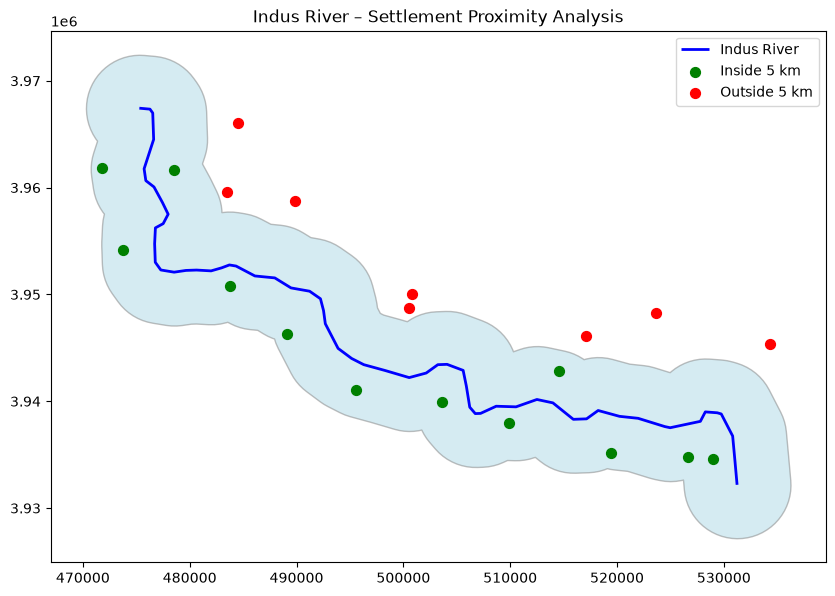

In [11]:
# Visualize proximity

fig, ax = plt.subplots(figsize=(10, 7))

buffer_5km.plot(
    ax=ax,
    color="lightblue",
    edgecolor="gray",
    alpha=0.5
)

indus.plot(
    ax=ax,
    color="blue",
    linewidth=2,
    label="Indus River"
)

settlements[settlements["Within_5km"]].plot(
    ax=ax,
    color="green",
    markersize=50,
    label="Inside 5 km"
)

settlements[~settlements["Within_5km"]].plot(
    ax=ax,
    color="red",
    markersize=50,
    label="Outside 5 km"
)

ax.set_title("Indus River – Settlement Proximity Analysis")
ax.legend()
plt.show()

In [12]:
# 8. Clip

nearby_settlements = gpd.clip(
    settlements,
    buffer_5km
)

print(nearby_settlements.head())
print("\nNearby settlements:", len(nearby_settlements))

     Settlement  Population     Type                        geometry  Dist_km  \
0  Settlement_A        1200  Village  POINT (529016.904 3934613.894)     2.00   
2  Settlement_C         850  Village  POINT (526607.075 3934809.721)     2.99   
4  Settlement_E        1600  Village  POINT (519460.272 3935169.126)     3.51   
6  Settlement_G         950  Village  POINT (509881.689 3938004.421)     1.50   
8  Settlement_I        1800  Village  POINT (503614.573 3939917.139)     2.49   

   Within_5km  
0        True  
2        True  
4        True  
6        True  
8        True  

Nearby settlements: 12


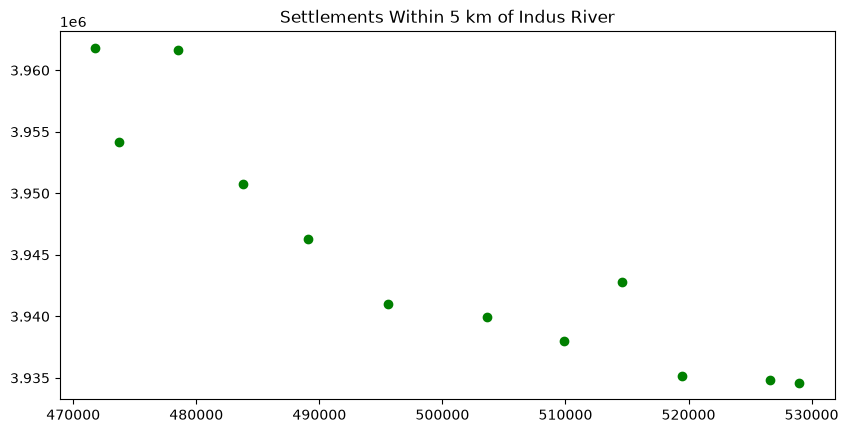

In [13]:
nearby_settlements.plot(
    figsize=(10, 7),
    color="green"
)

plt.title("Settlements Within 5 km of Indus River")
plt.show()

In [14]:
# 9. Intersection

buffer_5km_gdf = gpd.GeoDataFrame(
    {"Buffer_km": [5]},
    geometry=buffer_5km,
    crs=indus.crs
)

study_area = gpd.read_file(
    "Indus_Study_Area.geojson"
)

study_area = study_area.to_crs(
    indus.crs
)

intersection = gpd.overlay(
    study_area,
    buffer_5km_gdf,
    how="intersection"
)

intersection.head()

,Study_Area,Buffer_km,geometry
0,Indus_Study_Area,5,"POLYGON ((471153.745 3964623.822, 470897.93 39..."


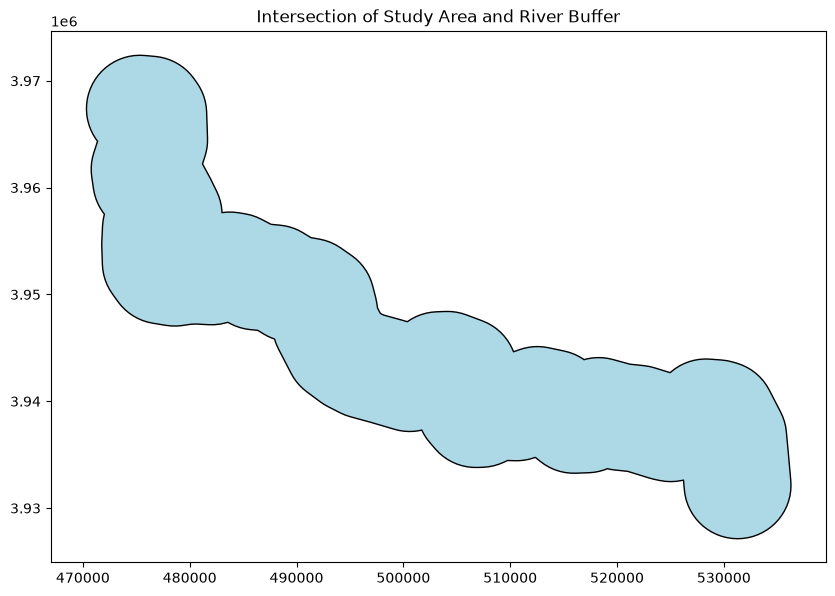

In [15]:
intersection.plot(
    figsize=(10, 7),
    color="lightblue",
    edgecolor="black"
)

plt.title("Intersection of Study Area and River Buffer")
plt.show()

In [16]:
# 10. Union

landuse = gpd.read_file(
    "Indus_Landuse.geojson"
)

landuse = landuse.to_crs(
    indus.crs
)

union = gpd.overlay(
    study_area,
    landuse,
    how="union"
)

union.head()

,Study_Area,Zone_ID,Landuse,geometry
0,Indus_Study_Area,1.0,Agriculture,"POLYGON ((466943.153 3919910.407, 466287.796 3..."
1,Indus_Study_Area,2.0,Agriculture,"POLYGON ((485604.531 3920558.187, 484937.283 3..."
2,Indus_Study_Area,3.0,Forest,"POLYGON ((504264.955 3921217.528, 503585.797 3..."
3,Indus_Study_Area,4.0,Built-up,"POLYGON ((522924.594 3921888.448, 522233.509 3..."
4,Indus_Study_Area,5.0,Agriculture,"POLYGON ((466287.796 3938971.492, 465633.63 39..."


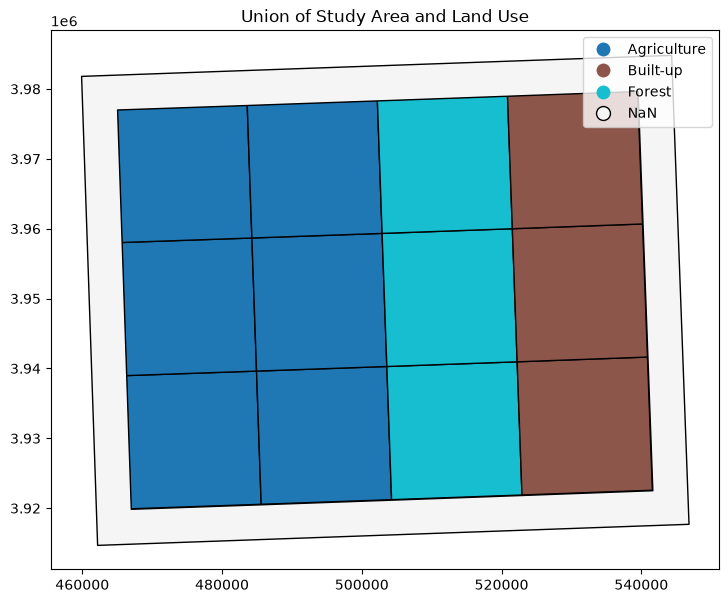

In [17]:
union.plot(
    column="Landuse",
    categorical=True,
    legend=True,
    figsize=(10, 7),
    edgecolor="black",
    missing_kwds={"color": "whitesmoke"}
)

plt.title("Union of Study Area and Land Use")
plt.show()

In [18]:
# 11. Dissolve

dissolved = landuse.dissolve(
    by="Landuse"
).reset_index()

dissolved["Area_km2"] = (
    dissolved.area / KM**2
).round(2)

dissolved[["Landuse", "Area_km2"]]

,Landuse,Area_km2
0,Agriculture,2133.24
1,Built-up,1066.52
2,Forest,1066.54


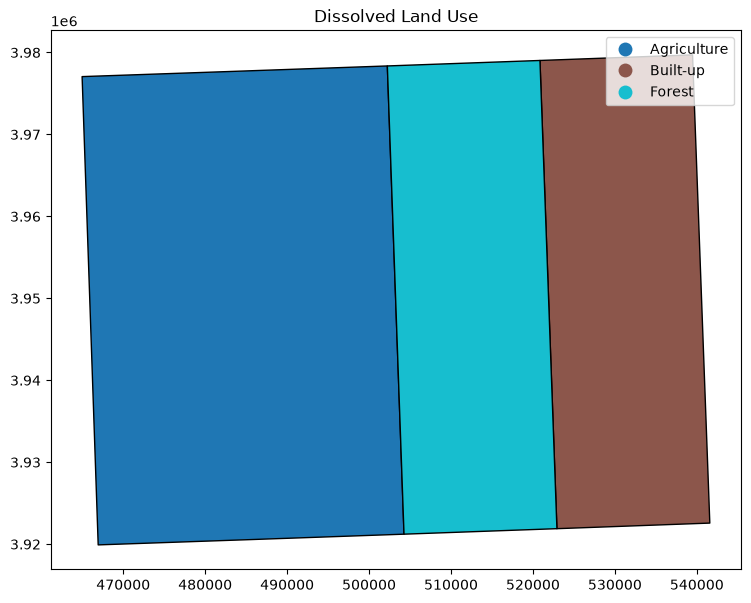

In [19]:
dissolved.plot(
    column="Landuse",
    categorical=True,
    legend=True,
    figsize=(10, 7),
    edgecolor="black"
)

plt.title("Dissolved Land Use")
plt.show()

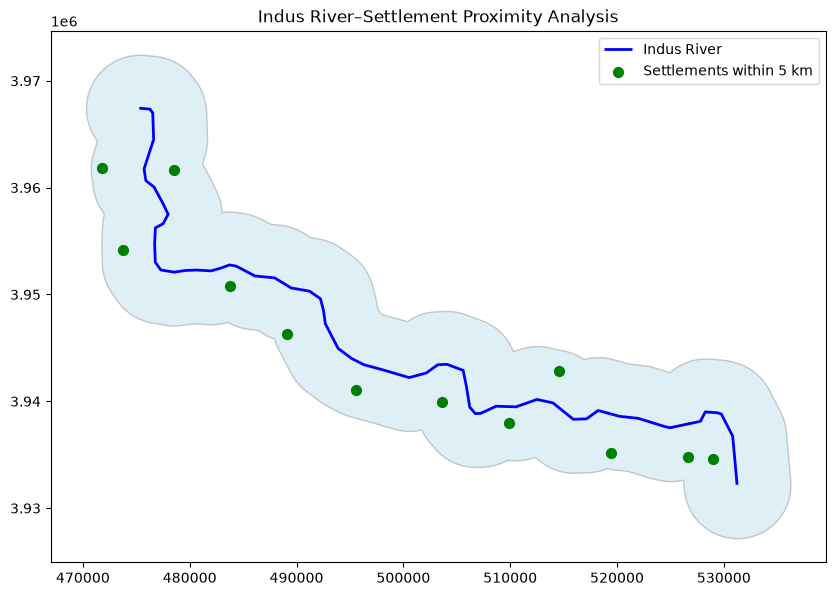

In [20]:
# 12. Final map (also saved as PNG)

fig, ax = plt.subplots(figsize=(10, 8))

buffer_5km.plot(
    ax=ax,
    color="lightblue",
    edgecolor="gray",
    alpha=0.4
)

indus.plot(
    ax=ax,
    color="blue",
    linewidth=2,
    label="Indus River"
)

nearby_settlements.plot(
    ax=ax,
    color="green",
    markersize=50,
    label="Settlements within 5 km"
)

ax.set_title(
    "Indus River–Settlement Proximity Analysis"
)

ax.legend()

plt.savefig(
    "Indus_River_Settlement_Proximity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
# 13. Export result

nearby_settlements.to_crs(
    "EPSG:4326"
).to_file(
    "Indus_Nearby_Settlements.geojson",
    driver="GeoJSON"
)

print("Result saved successfully.")

Result saved successfully.
